# Практическая работа № 10 — уровень A

Сегментация клиентов методом K-Means. Число кластеров задано шаблоном: `k=4`. Перед обучением все признаки стандартизируются.

Размеры кластеров:


,avg_check,purchases_month,days_since_last,discount_share,clients
cluster,,,,,
0,5037.63,6.15,3.78,0.09,59
1,884.42,6.94,6.14,0.59,220
2,1543.98,0.70,91.95,0.33,170
3,5229.86,1.47,27.21,0.16,151


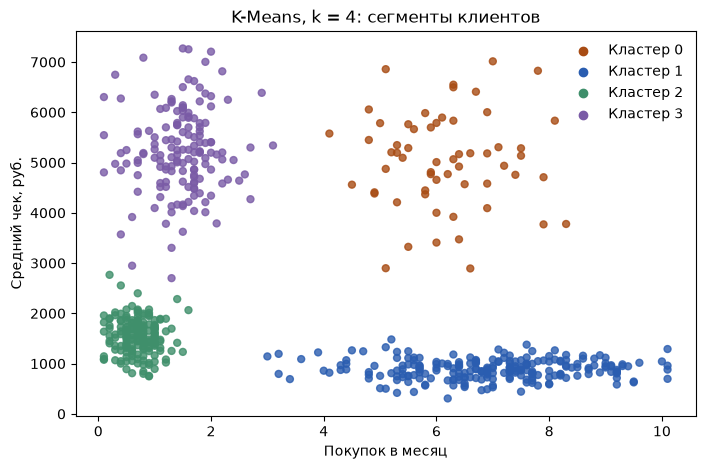

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

FEATURES = ['avg_check', 'purchases_month', 'days_since_last', 'discount_share']
COLORS = np.array(['#A84C14', '#2A5DB0', '#3F8F6B', '#7A5BA6'])

df = pd.read_csv('../raw/customers.csv')
assert set(FEATURES).issubset(df.columns)
assert not df[FEATURES].isna().any().any()

X = StandardScaler().fit_transform(df[FEATURES])
model = KMeans(n_clusters=4, n_init=20, random_state=42)
df['cluster'] = model.fit_predict(X)

profile = df.groupby('cluster')[FEATURES].mean().round(2)
profile['clients'] = df.groupby('cluster').size()
print('Размеры кластеров:')
display(profile)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['purchases_month'], df['avg_check'], c=COLORS[df['cluster']], s=25, alpha=0.8)
ax.set(title='K-Means, k = 4: сегменты клиентов', xlabel='Покупок в месяц', ylabel='Средний чек, руб.')
for cluster in range(4):
    ax.scatter([], [], c=COLORS[cluster], label=f'Кластер {cluster}')
ax.legend(frameon=False)
plt.show()

## Интерпретация сегментов

- **Кластер 0:** активные покупатели с высоким чеком, часто покупают без скидок.
- **Кластер 1:** частые покупатели с небольшим чеком, ориентированные на скидки.
- **Кластер 2:** неактивные клиенты с редкими покупками и давним последним визитом.
- **Кластер 3:** клиенты с высоким чеком, но редкими покупками.

Номера кластеров являются условными метками, а не рейтингом клиентов.